# Imports

In [2]:
import math
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

In [3]:
# Configurando gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [ ]:
# Selecionando o dispositivo (GPU se disponível, caso contrário CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Usando GPU: {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print("Usando CPU")

# CUDA só funciona com GPU da NVIDIA, então se você estiver usando uma GPU AMD, você precisará usar a CPU, como é meu caso.

Usando CPU


# Preparação dos Dados da Série Temporal

Aqui serão considerados dados fictícios, dado o propósito de aprendizado.

In [7]:
# Funçao para gerar uma série temporal sintética
def generate_synthetic_time_series(n_samples=1000, noise_std=0.1):

    # Vetor de tempo
    t = np.arange(n_samples)

    # Sinal senoidal de baixa frequência
    sin_wave_1 = np.sin(2 * np.pi * t / 50)

    # Sinal senoidal de frequência mais alta e menor amplitude
    sin_wave_2 = 0.5 * np.sin(2 * np.pi * t / 25)

    # Ruído aleatório gaussiano
    noise = np.random.normal(0, noise_std, n_samples)

    # Combinando os sinais e o ruído
    time_series = sin_wave_1 + sin_wave_2 + noise

    # Retornando a série temporal como tipo float32 para otimização de memória e compatibilidade com PyTorch
    return time_series.astype(np.float32)

In [8]:
# Executando a função para gerar a série temporal
time_series = generate_synthetic_time_series()

In [9]:
# Tamanho da série temporal
len(time_series)

1000

In [10]:
# Amostra dos primeiros 10 valores da série temporal
time_series[:10]

array([0.1965457 , 0.31011745, 0.642362  , 0.756774  , 0.94609094,
       1.175182  , 1.2234861 , 1.3023466 , 1.1790061 , 1.1872885 ],
      dtype=float32)

# Visualizando os Dados da Série Temporal

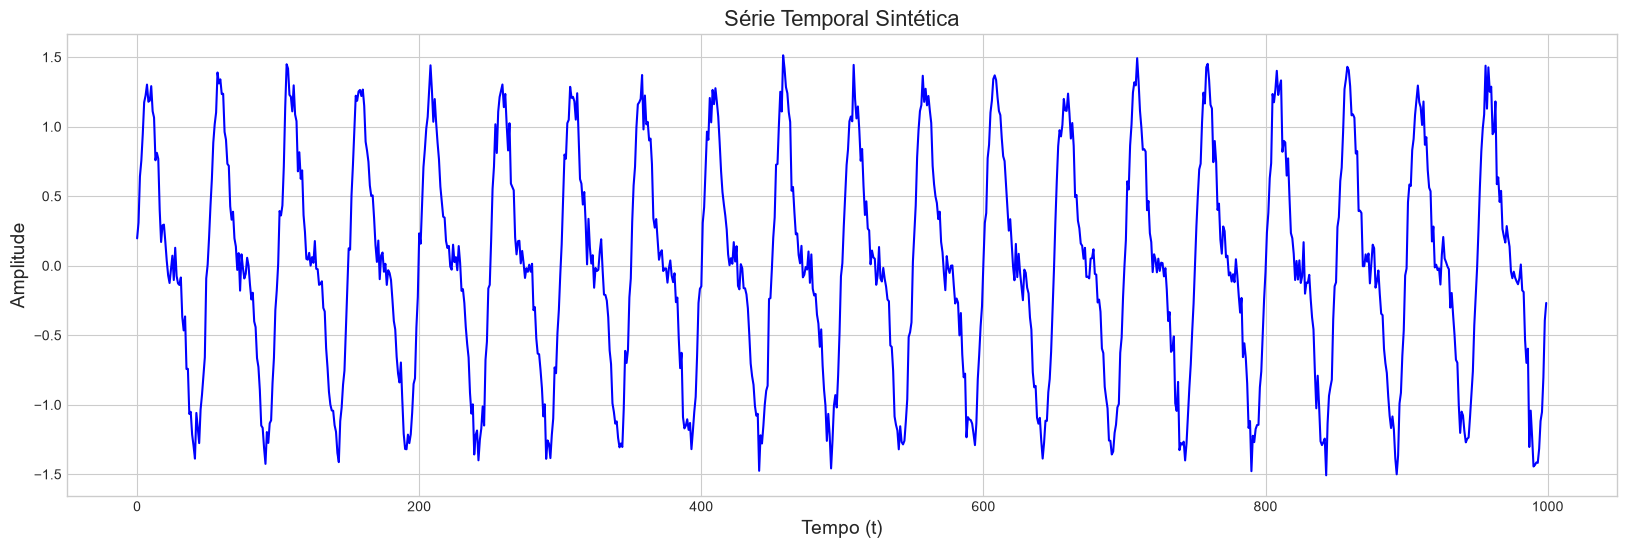

In [23]:
# Cria o eixo de tempo (mesmo tamanho da série temporal)
t = np.arange(len(time_series))

# Plotando a série temporal
plt.figure(figsize=(20, 6))
plt.plot(t, time_series, color='blue', linewidth=1.5)
plt.title('Série Temporal Sintética', fontsize=16)
plt.xlabel('Tempo (t)', fontsize=14)
plt.ylabel('Amplitude', fontsize=14)
plt.grid(True)
plt.show()

Analisando os componentes separadamente

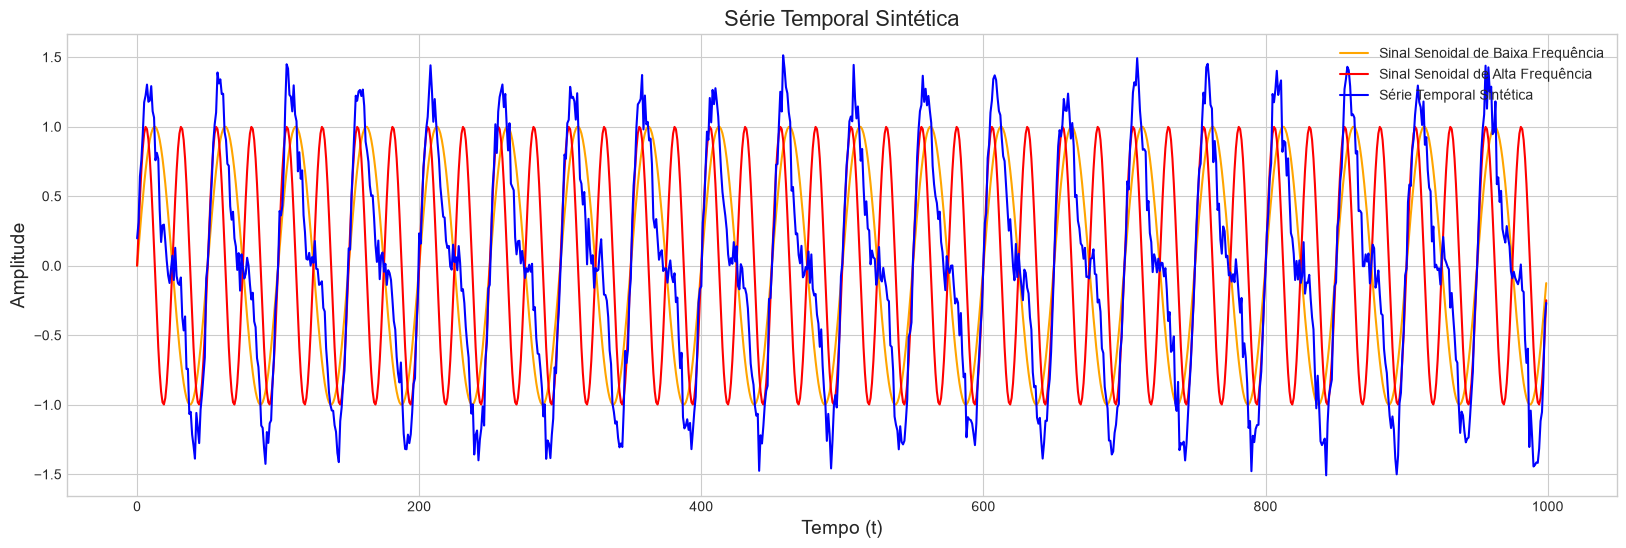

In [27]:
plt.figure(figsize=(20, 6))
plt.plot(t, np.sin(2 * np.pi * t / 50), color='orange', linewidth=1.5, label='Sinal Senoidal de Baixa Frequência')
plt.plot(t, np.sin(2 * np.pi * t / 25), color='red', linewidth=1.5, label='Sinal Senoidal de Alta Frequência')
plt.plot(t, time_series, color='blue', linewidth=1.5, label='Série Temporal Sintética')
plt.title('Série Temporal Sintética', fontsize=16)
plt.xlabel('Tempo (t)', fontsize=14)
plt.ylabel('Amplitude', fontsize=14)
plt.grid(True)
plt.legend()
plt.show()